# 01 - Análise Exploratória: Indicador Criança Alfabetizada

**Objetivo:** entender como a alfabetização ao final do 2º ano se distribui no Brasil, quais
fatores educacionais, territoriais e socioeconômicos estão associados a ela e quais
decisões de modelagem os dados justificam.

**Bases usadas** (geradas por `src/preprocessing/`):
- `data/gold/alunos.parquet` - um registro por aluno avaliado (Gold da Fase 2), alvo `atingiu_ponto_corte` (proficiência ≥ 743)
- `data/gold/painel_municipio_rede.parquet` - resultado agregado por município × rede × ano + features
  de Censo Escolar, Indicadores Educacionais, INSE, IBGE e Atlas IDHM

Todas as taxas são **ponderadas por `peso_aluno`**, como faz o Inep.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DIR_GOLD, DIR_RAW
from src.visualization import graficos as g

g.configurar_estilo()
pd.set_option("display.float_format", "{:.2f}".format)

painel = pd.read_parquet(DIR_GOLD / "painel_municipio_rede.parquet")
alunos = pd.read_parquet(
    DIR_GOLD / "alunos.parquet",
    columns=["ano", "id_municipio", "rede", "atingiu_ponto_corte", "peso_aluno", "sigla_uf", "nome_regiao"],
)
alunos = alunos[alunos["rede"].isin(["2", "3"])]
alunos["rede_nome"] = alunos["rede"].map({"2": "estadual", "3": "municipal"})


def taxa_ponderada(df):
    return np.average(df["atingiu_ponto_corte"], weights=df["peso_aluno"]) * 100


print(f"alunos avaliados: {len(alunos):,} | linhas do painel: {len(painel):,}")

alunos avaliados: 3,354,637 | linhas do painel: 12,416


## 1. O alvo e a visão nacional

In [2]:
bruta = pd.read_parquet(DIR_RAW / "alunos.parquet", columns=["ano", "presenca", "proficiencia"])
resumo_alvo = pd.DataFrame({
    "alunos na base": bruta.groupby("ano").size(),
    "ausentes / sem nota": bruta.groupby("ano")["proficiencia"].apply(lambda s: s.isna().sum()),
    "avaliados (modelagem)": alunos.groupby("ano").size(),
    "% alfabetizados (sem peso)": alunos.groupby("ano")["atingiu_ponto_corte"].mean() * 100,
    "% alfabetizados (ponderado)": alunos.groupby("ano").apply(taxa_ponderada, include_groups=False),
})
del bruta
resumo_alvo

,alunos na base,ausentes / sem nota,avaliados (modelagem),% alfabetizados (sem peso),% alfabetizados (ponderado)
ano,,,,,
2023,1747439,244630,1502809,58.39,57.46
2024,2120560,268708,1851828,59.78,59.20


**Leitura:** cerca de 14% dos alunos da base faltaram ou não tiveram o caderno preenchido e ficam fora
da modelagem (não há como saber se estão alfabetizados). Entre os avaliados, as classes são
razoavelmente equilibradas (~58% alfabetizados / ~42% não), então não há necessidade de reamostragem,
mas as métricas devem olhar as duas classes. A taxa ponderada de 2024 (59,2%) bate exatamente com
o número oficial do Inep - a reconstrução da Gold está correta.

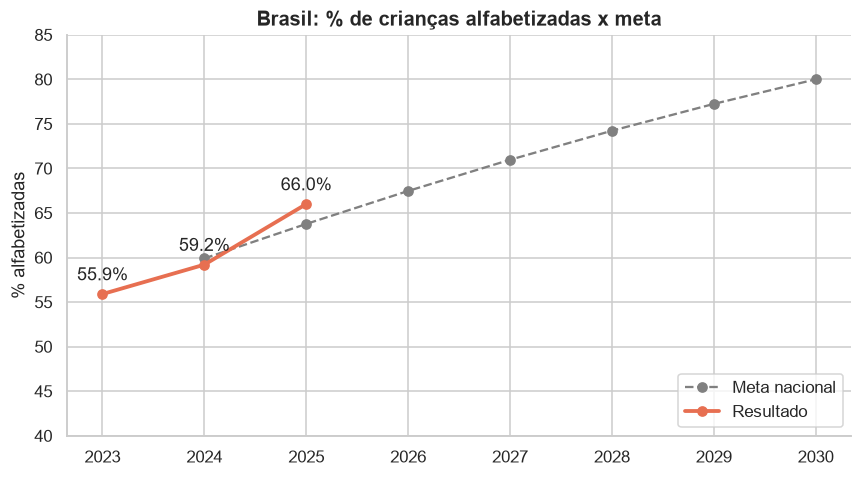

In [3]:
metas_brasil = pd.read_parquet(DIR_RAW / "meta_alfabetizacao_brasil.parquet")
oficial = metas_brasil.set_index("ano")["taxa_alfabetizacao"].sort_index()
edicao_2024 = metas_brasil[metas_brasil["ano"] == 2024].iloc[0]
trajetoria = pd.Series({ano: edicao_2024[f"meta_alfabetizacao_{ano}"] for ano in range(2024, 2031)})
g.trajetoria_brasil(oficial, trajetoria, salvar="eda_01_trajetoria_brasil");

**Leitura:** o Brasil ficou 0,7 p.p. abaixo da meta em 2024, mas o resultado oficial de 2025 (66%,
publicado pelo Inep e presente na tabela de metas) já superou a meta do ano (63,8%). O desafio
até 2030 é ganhar mais ~14 p.p. - e, como mostram as próximas seções, de forma muito desigual.

## 2. Desigualdade territorial

,sigla_uf,nome_regiao,taxa
4,BA,Nordeste,35.96
23,SE,Nordeste,38.39
19,RN,Nordeste,39.29
10,MG,Sudeste,72.08
8,GO,Centro-Oeste,72.74
5,CE,Nordeste,85.31


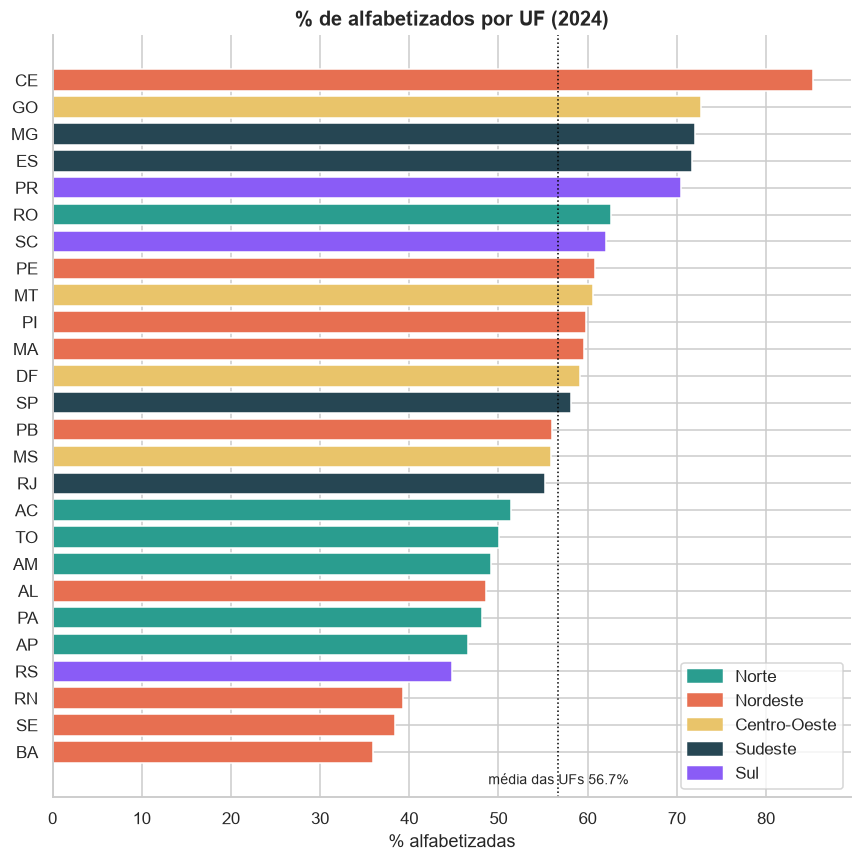

In [4]:
por_uf = (
    alunos[alunos["ano"] == 2024]
    .groupby(["sigla_uf", "nome_regiao"])
    .apply(taxa_ponderada, include_groups=False)
    .rename("taxa").reset_index()
)
g.barras_uf(por_uf, "taxa", salvar="eda_02_taxa_por_uf", titulo="% de alfabetizados por UF (2024)");
por_uf.sort_values("taxa").iloc[[0, 1, 2, -3, -2, -1]]

**Leitura:** a diferença entre UFs é enorme - de 36% (BA) a 85% (CE), quase 50 p.p. O Ceará,
com renda e INSE abaixo da média nacional, é o melhor do país: um forte indício de que **política
educacional estadual** (o PAIC, programa de alfabetização em regime de colaboração Estado-municípios,
existe desde 2007) pesa tanto quanto o contexto socioeconômico. Por isso a **UF entra como feature**
no modelo, representando o efeito de política/gestão estadual.

,count,mean,25%,50%,75%
nome_regiao,,,,,
Norte,435.00,49.41,38.21,49.20,59.39
Nordeste,1780.00,56.30,38.34,52.63,73.30
Centro-Oeste,464.00,72.35,61.10,73.35,83.61
Sudeste,1620.00,70.04,60.00,70.65,80.55
Sul,1136.00,63.83,52.12,66.09,76.47


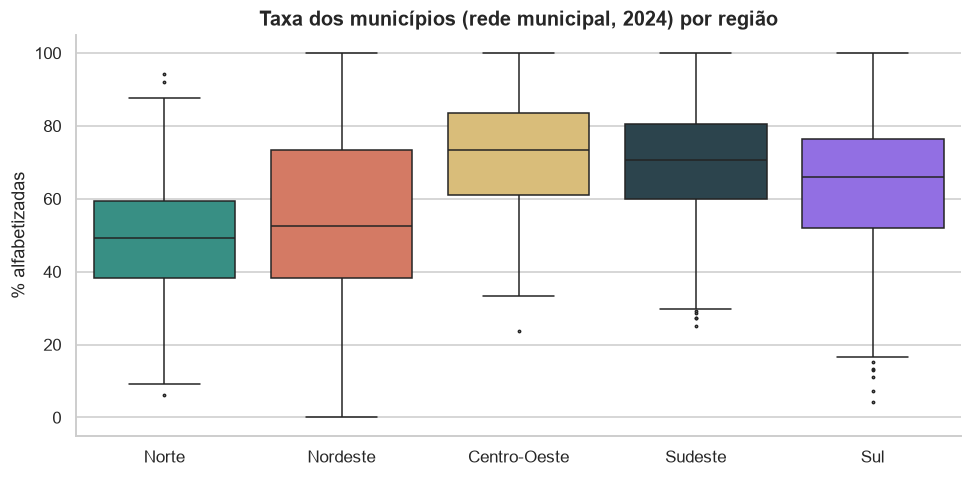

In [5]:
municipios_2024 = painel[(painel["ano"] == 2024) & (painel["rede"] == "3") & (painel["alunos_avaliados"] >= 10)]
ordem = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
g.distribuicao_por_grupo(municipios_2024, "taxa_alfabetizacao", "nome_regiao", ordem=ordem,
                         salvar="eda_03_municipios_por_regiao",
                         titulo="Taxa dos municípios (rede municipal, 2024) por região");
municipios_2024.groupby("nome_regiao")["taxa_alfabetizacao"].describe()[["count", "mean", "25%", "50%", "75%"]].loc[ordem]

**Leitura:** dentro de cada região a dispersão entre municípios é maior que a diferença entre
regiões (no Nordeste o intervalo interquartil vai de 38% a 73%). Centro-Oeste e Sudeste têm as
medianas mais altas, o Norte a mais baixa.

municípios já acima de 80%: 21.0%
municípios abaixo de 50%:   27.3%


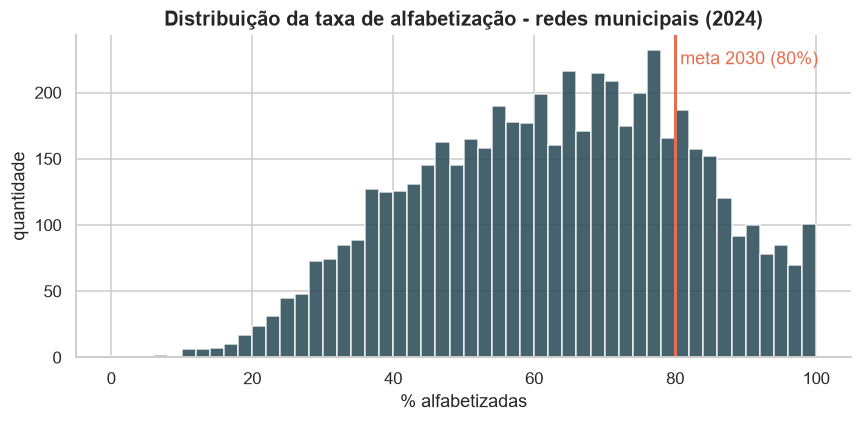

In [6]:
g.histograma(municipios_2024["taxa_alfabetizacao"], linha=80, rotulo_linha="meta 2030 (80%)",
             salvar="eda_04_hist_municipios",
             titulo="Distribuição da taxa de alfabetização - redes municipais (2024)",
             xlabel="% alfabetizadas");
print(f"municípios já acima de 80%: {(municipios_2024['taxa_alfabetizacao'] >= 80).mean():.1%}")
print(f"municípios abaixo de 50%:   {(municipios_2024['taxa_alfabetizacao'] < 50).mean():.1%}")

**Leitura:** 21% das redes municipais já estão acima da meta de 2030 (80%), enquanto 27% ainda
alfabetizam menos da metade das crianças - é nesse grupo que um modelo de risco tem mais valor.

In [7]:
por_rede = (
    alunos.groupby(["ano", "nome_regiao", "rede_nome"])
    .apply(taxa_ponderada, include_groups=False)
    .unstack("rede_nome").round(1)
)
por_rede

rede_nome          estadual  municipal
ano  nome_regiao                      
2023 Centro-Oeste     49.40      59.30
     Nordeste         44.00      53.90
     Norte            58.10      49.30
     Sudeste          64.30      57.00
     Sul              61.70      67.60
2024 Centro-Oeste     58.20      65.20
     Nordeste         47.30      56.70
     Norte            55.60      49.30
     Sudeste          68.60      60.30
     Sul              51.30      61.70

**Leitura:** não existe uma rede sistematicamente melhor: a municipal supera a estadual no Sul,
Nordeste e Centro-Oeste, e o inverso ocorre no Norte e Sudeste. A rede entra no modelo, mas
**combinada com a UF/região** (o modelo de árvores capta essa interação).

## 3. Fatores associados à alfabetização

,taxa_abandono_ef_anos_iniciais,tdi_ef_anos_iniciais,pct_alunos_inse_baixo,prop_pobreza_criancas,escolas_com_2_ano,indice_gini,pct_alunos_area_diferenciada,alunos_por_docente_ai,pct_alunos_escola_rural,taxa_criancas_dom_sem_fund,...,pct_agua_potavel,pct_quadra_esportes,idhm_r,renda_pc,dsu_ef_anos_iniciais,pct_biblioteca_ou_sala_leitura,idhm_l,idhm_e,idhm,inse_medio
spearman,-0.40,-0.39,-0.29,-0.26,-0.25,-0.23,-0.22,-0.21,-0.20,-0.19,...,0.18,0.22,0.22,0.22,0.23,0.25,0.25,0.25,0.26,0.29


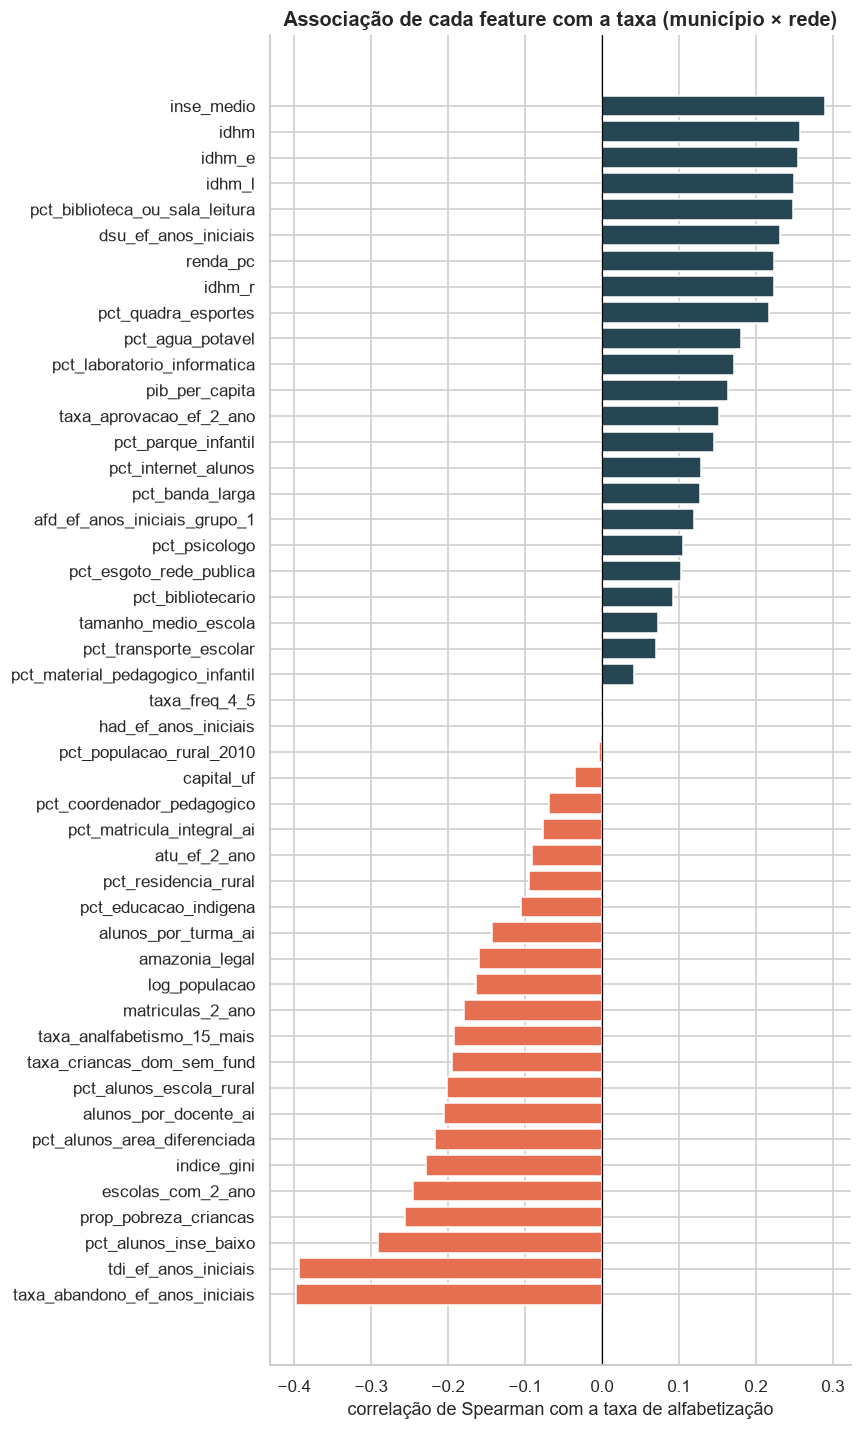

In [8]:
NAO_FEATURES = {
    "ano", "id_municipio", "rede", "rede_nome", "nome_municipio", "sigla_uf", "nome_regiao",
    "alunos_avaliados", "alunos_alfabetizados", "taxa_alfabetizacao", "taxa_ano_anterior",
}
base_corr = painel[painel["alunos_avaliados"] >= 10]
features_numericas = [col for col in base_corr.select_dtypes("number").columns if col not in NAO_FEATURES]
correlacoes = base_corr[features_numericas].corrwith(base_corr["taxa_alfabetizacao"], method="spearman")
g.correlacoes_com_alvo(correlacoes, salvar="eda_05_correlacoes",
                       titulo="Associação de cada feature com a taxa (município × rede)");
correlacoes.sort_values().to_frame("spearman").T

**Leitura:** as associações mais fortes são com **trajetória escolar** (abandono e distorção
idade-série: -0,40 e -0,39) e **nível socioeconômico** (INSE, pobreza infantil, IDHM, Gini). Em
seguida aparecem **infraestrutura pedagógica** (biblioteca/sala de leitura, quadra, laboratório)
e **formação docente** (docentes com superior). Redes **rurais, em áreas diferenciadas (indígenas,
quilombolas, assentamentos)** e com mais alunos por docente têm resultados piores. Nenhuma
correlação isolada passa de 0,4 → o fenômeno é multifatorial, o que favorece modelos não lineares.

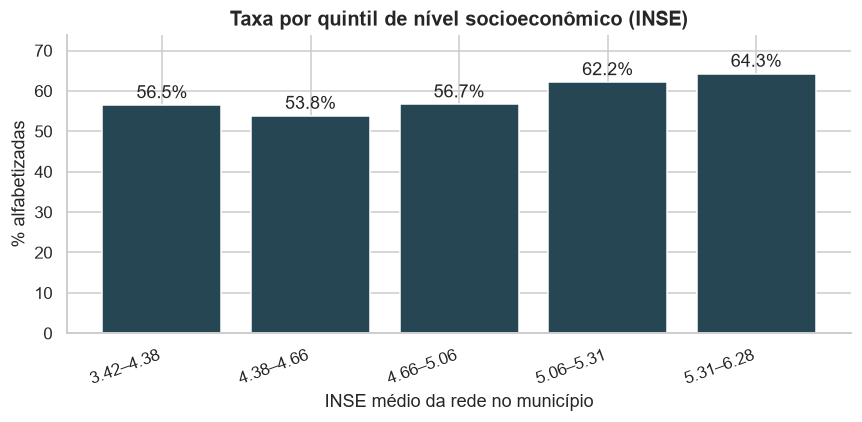

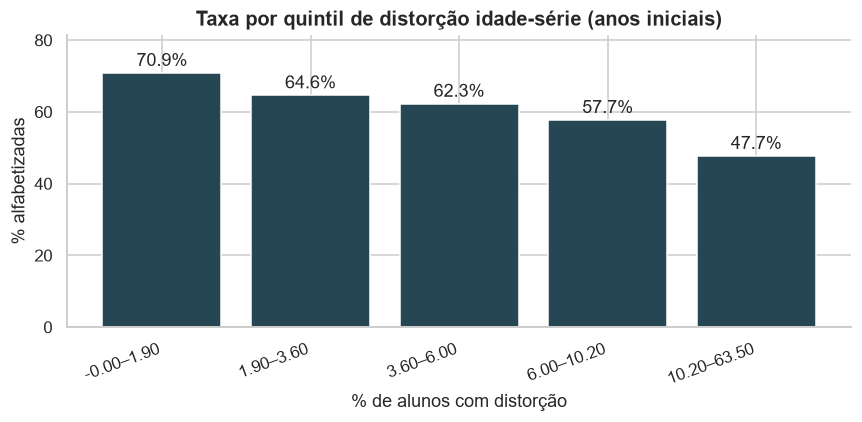

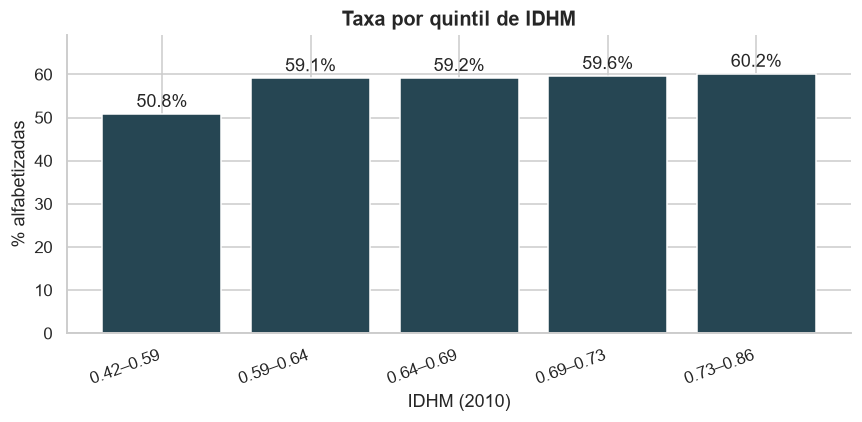

In [9]:
painel_peso = base_corr.assign(taxa=base_corr["taxa_alfabetizacao"])
g.taxa_por_faixa(painel_peso, "inse_medio", "taxa", "alunos_avaliados", salvar="eda_06_faixas_inse",
                 titulo="Taxa por quintil de nível socioeconômico (INSE)", xlabel="INSE médio da rede no município");
g.taxa_por_faixa(painel_peso, "tdi_ef_anos_iniciais", "taxa", "alunos_avaliados", salvar="eda_07_faixas_distorcao",
                 titulo="Taxa por quintil de distorção idade-série (anos iniciais)", xlabel="% de alunos com distorção");
g.taxa_por_faixa(painel_peso, "idhm", "taxa", "alunos_avaliados", salvar="eda_08_faixas_idhm",
                 titulo="Taxa por quintil de IDHM", xlabel="IDHM (2010)");

**Leitura:** a distorção idade-série tem o gradiente mais limpo e monotônico. O INSE e o IDHM
mostram efeito mais fraco nos quintis inferiores - justamente porque redes pobres com política
forte (CE, PE, PI, MA) puxam a média para cima. Isso reforça que **o modelo precisa combinar
socioeconomia com território**.

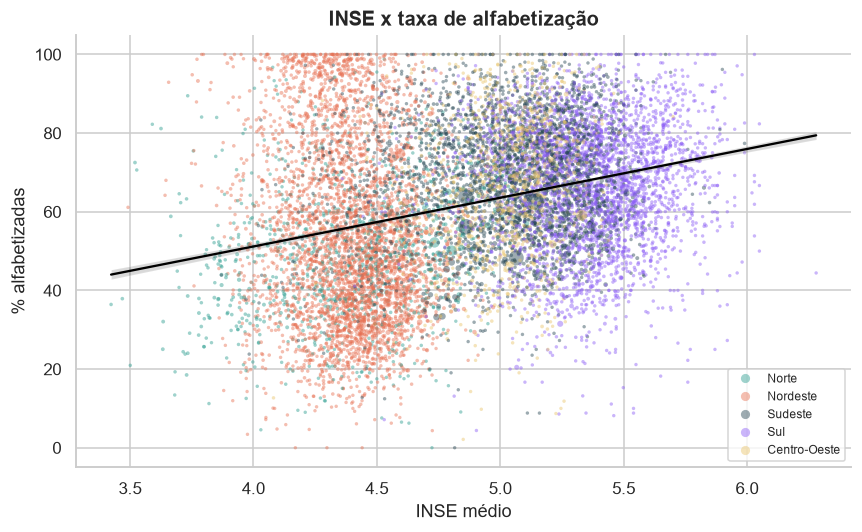

In [10]:
g.dispersao_por_regiao(base_corr, "inse_medio", "taxa_alfabetizacao", tamanho="alunos_avaliados",
                       salvar="eda_09_dispersao_inse", titulo="INSE x taxa de alfabetização",
                       xlabel="INSE médio");

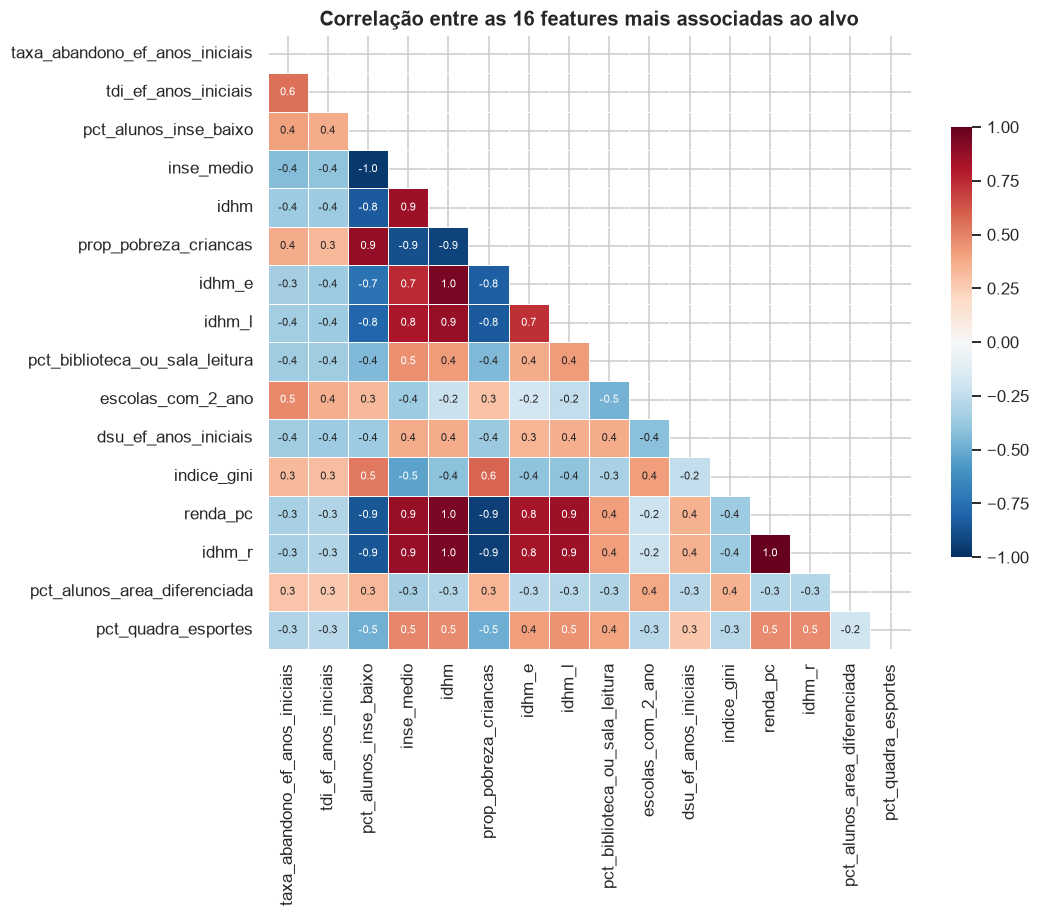

In [11]:
top = correlacoes.abs().sort_values(ascending=False).head(16).index
g.heatmap_correlacao(base_corr[top], salvar="eda_10_heatmap",
                     titulo="Correlação entre as 16 features mais associadas ao alvo");

**Leitura:** há blocos de **multicolinearidade** forte - IDHM e seus componentes, pobreza infantil,
Gini e analfabetismo adulto medem praticamente a mesma coisa. Para o modelo de árvores isso não
prejudica a predição, mas **dilui a importância** entre variáveis parecidas; na interpretação (SHAP)
elas devem ser lidas em grupo. Na regressão logística (baseline) a regularização L2 cuida do problema.

## 4. Persistência temporal (2023 → 2024)

municípios com os dois anos: 4,503
correlação 2023 x 2024: 0.67
variação média: +2.9 p.p. | desvio: 16.1 p.p.
variação no 1º quintil de 2023: +11.2 p.p. | no 5º quintil: -7.8 p.p.


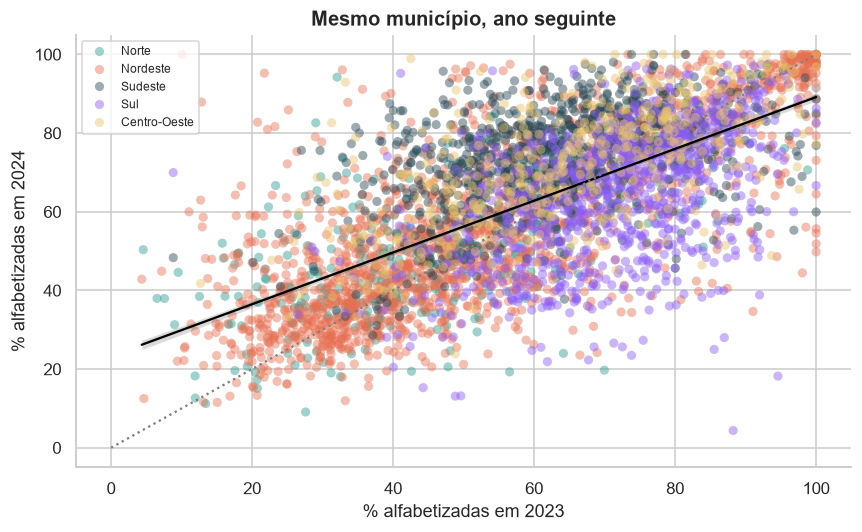

In [12]:
municipal = painel[(painel["rede"] == "3") & (painel["alunos_avaliados"] >= 20)]
pares = (
    municipal.pivot_table(index=["id_municipio", "nome_regiao"], columns="ano", values="taxa_alfabetizacao")
    .dropna().reset_index()
)
pares.columns = ["id_municipio", "nome_regiao", "taxa_2023", "taxa_2024"]
fig = g.dispersao_por_regiao(pares, "taxa_2023", "taxa_2024", titulo="Mesmo município, ano seguinte",
                             xlabel="% alfabetizadas em 2023", ylabel="% alfabetizadas em 2024")
fig.axes[0].plot([0, 100], [0, 100], color="grey", linestyle=":")
fig.savefig(g.DIR_IMAGENS / "eda_11_persistencia.png")

print(f"municípios com os dois anos: {len(pares):,}")
print(f"correlação 2023 x 2024: {pares[['taxa_2023', 'taxa_2024']].corr().iloc[0, 1]:.2f}")
variacao = pares["taxa_2024"] - pares["taxa_2023"]
print(f"variação média: {variacao.mean():+.1f} p.p. | desvio: {variacao.std():.1f} p.p.")
q_baixo = pares["taxa_2023"] <= pares["taxa_2023"].quantile(0.2)
q_alto = pares["taxa_2023"] >= pares["taxa_2023"].quantile(0.8)
print(f"variação no 1º quintil de 2023: {variacao[q_baixo].mean():+.1f} p.p. | no 5º quintil: {variacao[q_alto].mean():+.1f} p.p.")

**Leitura:** a taxa do ano anterior é o melhor preditor isolado (ρ ≈ 0,67), mas há forte
**regressão à média**: municípios no quintil mais baixo em 2023 subiram +11 p.p. e os do mais
alto caíram -8 p.p. Boa parte disso é ruído amostral de redes pequenas (poucos alunos avaliados).
Implicações: (1) para prever metas futuras, a taxa anterior é útil, mas deve vir acompanhada do
**tamanho da rede** (nº de alunos) para o modelo saber quanto confiar nela; (2) rankings de risco
devem considerar incerteza em municípios pequenos.

## 5. Metas municipais

In [13]:
metas_mun = pd.read_parquet(DIR_RAW / "meta_alfabetizacao_municipio.parquet")
metas_mun = metas_mun.sort_values("ano").drop_duplicates("id_municipio", keep="last")
metas = municipios_2024.merge(
    metas_mun[["id_municipio", "meta_alfabetizacao_2024", "meta_alfabetizacao_2025", "nivel_alfabetizacao"]],
    on="id_municipio", how="inner",
).dropna(subset=["meta_alfabetizacao_2024"])
metas["atingiu_meta_2024"] = metas["taxa_alfabetizacao"] >= metas["meta_alfabetizacao_2024"]
metas["distancia_meta_2025"] = metas["taxa_alfabetizacao"] - metas["meta_alfabetizacao_2025"]

print(f"municípios com meta 2024 definida: {len(metas):,}")
print(f"atingiram a meta de 2024: {metas['atingiu_meta_2024'].mean():.1%}")
print(f"já estão acima da meta de 2025: {(metas['distancia_meta_2025'] >= 0).mean():.1%}")
metas.groupby("nome_regiao")["atingiu_meta_2024"].mean().mul(100).round(1).loc[ordem].to_frame("% que atingiu a meta 2024")

municípios com meta 2024 definida: 5,225
atingiram a meta de 2024: 53.4%
já estão acima da meta de 2025: 44.2%


,% que atingiu a meta 2024
nome_regiao,
Norte,44.20
Nordeste,50.20
Centro-Oeste,73.10
Sudeste,66.20
Sul,34.00


**Leitura:** só 53% das redes municipais atingiram a meta de 2024. O Sul tem o pior desempenho
relativo (34%) apesar de taxas medianas razoáveis - houve queda de 2023 para 2024 (no RS, ano das
enchentes, a taxa estadual ficou em 45%). Isso mostra que **prever "atingir a meta" é diferente de
prever "taxa alta"**: depende do ponto de partida e da ambição da meta.

## 6. Dados faltantes

In [14]:
ausentes = painel[features_numericas + ["taxa_ano_anterior"]].isna().mean().mul(100)
ausentes[ausentes > 0].sort_values(ascending=False).round(1).to_frame("% ausente")

,% ausente
taxa_ano_anterior,54.00
pct_alunos_inse_baixo,4.50
inse_medio,1.40
atu_ef_2_ano,0.50
afd_ef_anos_iniciais_grupo_1,0.20
taxa_aprovacao_ef_2_ano,0.20
taxa_freq_4_5,0.10
taxa_criancas_dom_sem_fund,0.10
idhm_l,0.10
idhm_e,0.10


**Leitura:** fora a taxa do ano anterior (inexistente para 2023 por construção), os ausentes
são poucos (< 5%) e concentrados em INSE (escolas sem alunos suficientes no Saeb) e em
indicadores de redes estaduais muito pequenas. Decisão: **imputação pela mediana dentro do
pipeline** (ajustada só no treino) + `add_indicator=True`, para o modelo saber quando um valor foi
imputado.

## 7. Hipóteses e decisões de modelagem

| # | Hipótese (da EDA) | Como entra na modelagem |
|---|---|---|
| H1 | Trajetória escolar (distorção idade-série, abandono) é o fator mais associado | features `tdi_*`, `taxa_abandono_*` (ano 2022, anterior às provas) |
| H2 | Nível socioeconômico importa, mas é modulado pela política estadual | INSE, IDHM, pobreza **+ UF** como feature categórica |
| H3 | Infraestrutura pedagógica e formação docente fazem diferença | % biblioteca/leitura, laboratório, docentes com superior, alunos/docente |
| H4 | Redes rurais e de áreas diferenciadas têm maior risco | % alunos em escola rural, área diferenciada, educação indígena |
| H5 | Histórico recente prevê o futuro, com ruído em redes pequenas | `taxa_ano_anterior` + nº de alunos **só no modelo de metas municipais** |

**Decisões contra data leakage:**
- `proficiencia` e a coluna `alfabetizado` da fonte **nunca** entram como features (definem o alvo).
- Todas as features externas usam dados **anteriores** à avaliação (ver tabela em `construir_features.py`).
- Metas municipais não entram no modelo de alunos (a meta 2024 foi calculada a partir do resultado de 2023).
- **Validação temporal:** treino com a avaliação de 2023, teste com a de 2024 - simula o uso real
  (prever o próximo ciclo) e garante que nenhum dado do teste influencia o treino.
- O `id_escola` é anonimizado e não cruza com o Censo → o contexto entra no nível **município × rede**;
  para medir generalização para municípios nunca vistos, a validação cruzada usa `GroupKFold` por município.